# Exploration 1 - Rotational transform (iota) in ConStellaration

Physics recap (session 2): the rotational transform `iota` counts how many poloidal turns a field line
makes per toroidal turn. The dataset stores it **divided by the number of field periods** `NFP`:

| column | meaning |
|---|---|
| `metrics.axis_rotational_transform_over_n_field_periods` | iota on the magnetic axis / NFP |
| `metrics.edge_rotational_transform_over_n_field_periods` | iota at the plasma edge / NFP |
| `metrics.aspect_ratio` | aspect ratio A = R / a |
| `metrics.aspect_ratio_over_edge_rotational_transform` | A / iota_edge (iota **not** divided by NFP) |
| `boundary.n_field_periods` | NFP |

Definitions checked in the official code, `constellaration/forward_model.py`:
`aspect_ratio_over_edge_rotational_transform = aspect / edge_rotational_transform` and
`edge_rotational_transform_over_n_field_periods = edge_rotational_transform / n_field_periods`.

Goals:
1. compute iota_axis, iota_edge and the shear proxy delta_iota = iota_edge - iota_axis;
2. histogram of delta_iota: share of configurations where iota decreases outwards, share with almost no shear;
3. check A / iota_edge against the stored column on the whole dataset;
4. share of rows satisfying |iota_edge| / NFP >= 0.25 (benchmark constraint).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data/processed/constellaration.parquet")   # notebook stored in notebooks/

NFP = "boundary.n_field_periods"
AXIS = "metrics.axis_rotational_transform_over_n_field_periods"
EDGE = "metrics.edge_rotational_transform_over_n_field_periods"
ASPECT = "metrics.aspect_ratio"
A_OVER_IOTA = "metrics.aspect_ratio_over_edge_rotational_transform"

# Parquet is columnar: we read only the 5 columns we need (fast, low memory)
df = pd.read_parquet(DATA, columns=[NFP, AXIS, EDGE, ASPECT, A_OVER_IOTA])
print(f"rows loaded: {len(df)}")

rows loaded: 182222


## 0. Keep the rows that have metrics

About 23k configurations have no metrics (the physics code was not run or failed). They have NaN in the
metric columns and must be removed before any statistic.

In [2]:
n_before = len(df)
df = df.dropna(subset=[AXIS, EDGE, ASPECT, A_OVER_IOTA])
print(f"rows with metrics: {len(df)} ({n_before - len(df)} removed)")

rows with metrics: 158685 (23537 removed)


## 1. iota on the axis, at the edge, and the shear proxy

Multiply by NFP to get the true iota. Then delta_iota = iota_edge - iota_axis.

**Sign convention.** iota can be negative: the sign only says in which direction the field lines twist
(the benchmark itself uses the absolute value, see `problems.py`). To ask "does the twist grow or shrink
outwards?" we therefore compare **magnitudes**: `delta_abs = |iota_edge| - |iota_axis|`.
We first check whether negative values exist at all.

In [3]:
df["iota_axis"] = df[AXIS] * df[NFP]
df["iota_edge"] = df[EDGE] * df[NFP]
df["delta_iota"] = df["iota_edge"] - df["iota_axis"]
df["delta_abs"] = df["iota_edge"].abs() - df["iota_axis"].abs()

print(f"negative iota on the axis : {(df.iota_axis < 0).mean():.1%}")
print(f"negative iota at the edge : {(df.iota_edge < 0).mean():.1%}")
print(f"sign changes between axis and edge: {(np.sign(df.iota_axis) != np.sign(df.iota_edge)).mean():.1%}")
df[["iota_axis", "iota_edge", "delta_iota", "delta_abs"]].describe()

negative iota on the axis : 6.4%
negative iota at the edge : 6.4%
sign changes between axis and edge: 0.0%


,iota_axis,iota_edge,delta_iota,delta_abs
count,158685.000000,158685.000000,158685.000000,158685.000000
mean,0.617640,0.736361,0.118721,0.122101
std,0.400081,0.540916,0.347888,0.346713
min,-3.012705,-3.313158,-2.228330,-1.525170
25%,0.371279,0.413113,-0.064098,-0.061543
50%,0.610885,0.706071,0.021448,0.027076
75%,0.916539,1.012556,0.247944,0.248455
max,4.618068,4.946899,3.246450,3.246450


## 2. Histogram of the shear proxy

Two questions:
- what share of configurations has a twist that **decreases** outwards (`delta_abs < 0`)?
- what share has **almost no shear**?

**Methodological choice (to state in the report):** "almost no shear" has no official threshold.
We use a *relative* criterion: `|delta_abs| < 5 % of |iota_axis|`, and show 1 % and 10 % to see how
sensitive the answer is. A few extreme values would squash the histogram, so we plot the central 99 %
and report how many points fall outside.

twist decreasing outwards : 39.2%
almost no shear (|delta| < 1% of |iota_axis|): 2.2%
almost no shear (|delta| < 5% of |iota_axis|): 12.6%
almost no shear (|delta| < 10% of |iota_axis|): 27.7%


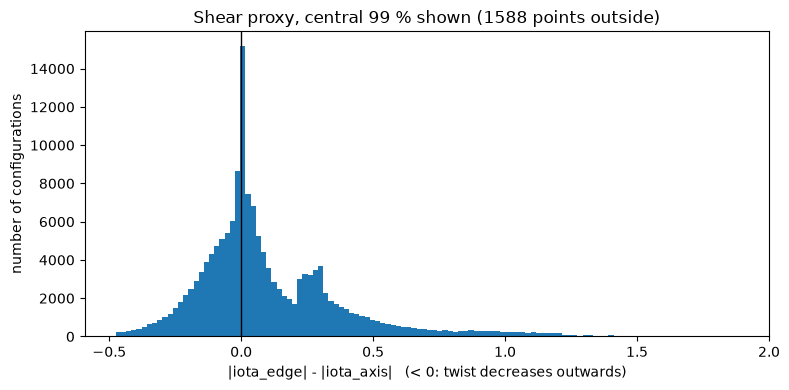

In [5]:
decreasing = (df.delta_abs < 0).mean()
print(f"twist decreasing outwards : {decreasing:.1%}")
for tol in [0.01, 0.05, 0.10]:
    flat = (df.delta_abs.abs() < tol * df.iota_axis.abs()).mean()
    print(f"almost no shear (|delta| < {tol:.0%} of |iota_axis|): {flat:.1%}")

lo, hi = df.delta_abs.quantile([0.005, 0.995])
inside = df.delta_abs.between(lo, hi)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df.delta_abs[inside], bins=120, color="#1f77b4")
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("|iota_edge| - |iota_axis|   (< 0: twist decreases outwards)")
ax.set_ylabel("number of configurations")
ax.set_title(f"Shear proxy, central 99 % shown ({(~inside).sum()} points outside)")
fig.tight_layout()
plt.show()

## 3. Consistency check: A / iota_edge

Recompute `aspect_ratio / iota_edge` (true iota, not divided by NFP) and compare it with the stored column.
We use the **relative** error because the values span a wide range. Float rounding gives errors around
1e-15; anything above 1e-6 deserves a look. Rows where iota_edge is close to 0 are fragile (division).

In [6]:
recomputed = df[ASPECT] / df["iota_edge"]
rel_err = (recomputed - df[A_OVER_IOTA]).abs() / df[A_OVER_IOTA].abs()
print(f"median relative error: {rel_err.median():.2e}")
print(f"max relative error   : {rel_err.max():.2e}")
print(f"rows with error > 1e-6: {(rel_err > 1e-6).sum()} / {len(df)}")
# the worst rows, to inspect by hand
df.assign(recomputed=recomputed, rel_err=rel_err).nlargest(5, "rel_err")[
    [NFP, ASPECT, "iota_edge", A_OVER_IOTA, "recomputed", "rel_err"]]

median relative error: 0.00e+00
max relative error   : 3.11e-16
rows with error > 1e-6: 0 / 158685


,boundary.n_field_periods,metrics.aspect_ratio,iota_edge,metrics.aspect_ratio_over_edge_rotational_transform,recomputed,rel_err
44408,5.0,7.593848,1.330009,5.709619,5.709619,3.111165e-16
124932,5.0,8.035294,2.658354,3.022658,3.022658,2.938402e-16
132037,3.0,9.267753,-0.023584,-392.972249,-392.972249,2.892999e-16
94127,5.0,8.661617,1.399907,6.187280,6.187280,2.870982e-16
9995,5.0,7.837050,1.261661,6.211694,6.211694,2.859698e-16


## 4. Benchmark constraint on iota

The constraint is written on the absolute value: `|iota_edge| / NFP >= bound` (`problems.py`).
The bound is **0.25** for the two QI problems (`SimpleToBuildQIStellarator`, `MHDStableQIStellarator`)
and **0.3** for `GeometricalProblem`. Note: the official evaluation also applies a 1 % tolerance
to its constraints; we ignore it here (simple count).

In [7]:
ratio = df[EDGE].abs()
for bound in [0.25, 0.30]:
    print(f"|iota_edge|/NFP >= {bound}: {(ratio >= bound).mean():.1%} of the rows")

# same count per NFP: does the constraint get harder when NFP grows?
(ratio >= 0.25).groupby(df[NFP]).agg(["mean", "size"]).rename(columns={"mean": "share_ok", "size": "n_rows"})

|iota_edge|/NFP >= 0.25: 35.7% of the rows
|iota_edge|/NFP >= 0.3: 26.5% of the rows


,share_ok,n_rows
boundary.n_field_periods,,
1.0,0.382556,14607
2.0,0.356781,19945
3.0,0.520523,68191
4.0,0.156810,27798
5.0,0.146674,28144


## Summary

Results on the 158,685 configurations with metrics (all NFP, all generation methods):

1. **Sign of iota.** 6.4 % of the configurations have a negative iota, on the axis and at the edge alike;
   the sign never changes between axis and edge (0.0 %). The sign only gives the twist direction, so
   magnitudes are compared below.
2. **Shear.** In 39.2 % of the configurations $|\iota|$ decreases from axis to edge (tokamak-like direction).
   There is no official threshold for "almost no shear": with $|\Delta\iota| < 1\,\%,\ 5\,\%,\ 10\,\%$ of
   $|\iota_{axis}|$ we get 2.2 %, 12.6 % and 27.7 % of the configurations. The histogram shows a sharp peak
   at $\Delta\iota \approx 0$ and a second bump around +0.25 to +0.3, possibly a sub-population
   (to be checked by generation method and NFP).
3. **Consistency check.** The stored `aspect_ratio_over_edge_rotational_transform` equals the aspect ratio
   divided by the *total* edge iota (stored per-period value × NFP) on all rows, to machine precision
   (max relative error $3.1\times10^{-16}$). It is a derived quantity; it diverges where $\iota_{edge}\to 0$
   (e.g. −393 for $\iota_{edge} = -0.024$).
4. **Benchmark constraint.** 35.7 % of the configurations satisfy $|\iota_{edge}|/N_{fp} \ge 0.25$ and
   26.5 % satisfy $\ge 0.3$. The share drops with NFP: 38 %, 36 %, 52 %, 16 %, 15 % for NFP = 1 to 5,
   since more field periods need more total twist for the same per-period bound.